# Diabetes Predictive Modeling

## Linear Classification

Is there a linear relationship between any health indicators and having a diabetes diagnosis?

2015 CDC Survey Data (balanced and clean)

In [16]:
from sklearn.svm import LinearSVC
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

### Download the diabetes dataset and subset it into training and test subsets, with separate sets for data and labels.

In [19]:
diabetes = pd.read_csv("diabetes_binary_5050split_health_indicators_BRFSS2015.csv")

# subset containing surveys of people without diabetes/prediabetes
diabetes_0 = diabetes[diabetes["Diabetes_binary"] == 0]
# subset containing surveys of people with diabetes/prediabetes
diabetes_1 = diabetes[diabetes["Diabetes_binary"] == 1]

diabetes_train_0 = diabetes_0.iloc[: 25000, 1:]
diabetes_label_0 = diabetes_0.iloc[: 25000, 0]

diabetes_train_1 = diabetes_1.iloc[: 25000, 1:]
diabetes_label_1 = diabetes_1.iloc[: 25000, 0]

diabetes_train_data = pd.concat([diabetes_train_0, diabetes_train_1], axis=0)
diabetes_train_labels = pd.concat([diabetes_label_0, diabetes_label_1], axis=0)

test_data_0 = diabetes_0.iloc[25000 :, 1:]
test_label_0 = diabetes_0.iloc[25000 :, 0]

test_data_1 = diabetes_1.iloc[25000 :, 1:]
test_label_1 = diabetes_1.iloc[25000 :, 0]

diabetes_test_data = pd.concat([test_data_0, test_data_1], axis=0)
diabetes_test_labels = pd.concat([test_label_0, test_label_1], axis=0)

#Shuffle, so all zeros don't come first and are followed by all ones
diabetes_train_data = diabetes_train_data.sample(frac=1, random_state=42)
diabetes_train_labels = diabetes_train_labels.reindex(diabetes_train_data.index)

diabetes_test_data = diabetes_test_data.sample(frac=1, random_state=42)
diabetes_test_labels = diabetes_test_labels.reindex(diabetes_test_data.index)

### Scale the data to ensure each health indicator holds the same value and is treated on the same scale. Fit the model and create predictions, as well as a confusion matrix to test accuracy, precision, recall, and F1 score of the model

In [22]:
scaler = StandardScaler()

scaled_train = scaler.fit_transform(diabetes_train_data)
scaled_test = scaler.transform(diabetes_test_data)

model = LinearSVC(C=0.1, random_state=42, max_iter=10000, dual=False)
model.fit(scaled_train, diabetes_train_labels)

pred_diabetes_train = model.predict(scaled_train)
pred_diabetes_test = model.predict(scaled_test)

cm = confusion_matrix(diabetes_test_labels, pred_diabetes_test) 
print(cm)

print(classification_report(
    diabetes_test_labels,
    pred_diabetes_test,
    target_names=["No diabetes", "Diabetes/prediabetes"]
))

print("Training accuracy:",
      accuracy_score(diabetes_train_labels, pred_diabetes_train))

print("Testing accuracy:",
      accuracy_score(diabetes_test_labels, pred_diabetes_test))

[[7454 2892]
 [2245 8101]]
                      precision    recall  f1-score   support

         No diabetes       0.77      0.72      0.74     10346
Diabetes/prediabetes       0.74      0.78      0.76     10346

            accuracy                           0.75     20692
           macro avg       0.75      0.75      0.75     20692
        weighted avg       0.75      0.75      0.75     20692

Training accuracy: 0.7464
Testing accuracy: 0.7517398028223468


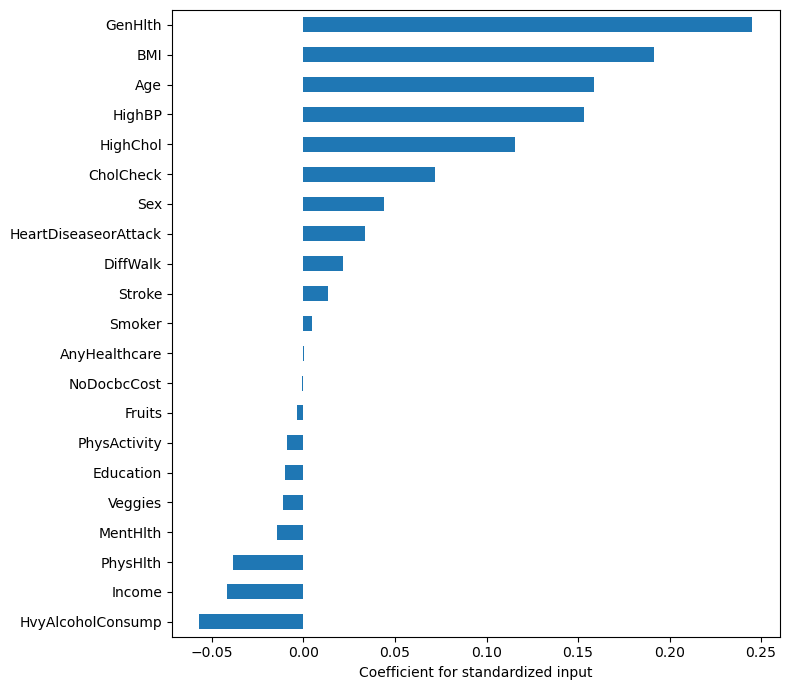

In [24]:
coefficients = pd.Series(
    model.coef_[0],
    index=diabetes_train_data.columns
)

coefficients.sort_values().plot.barh(figsize=(8, 7))
plt.xlabel("Coefficient for standardized input")
plt.tight_layout()
plt.show()